In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Load dataset
df = pd.read_csv("../Ontrac_data.csv")

sns.set_theme(style="whitegrid", palette="viridis")

# Assumes your dataset is already loaded into df
df.columns = df.columns.str.strip()

df["Products"] = df["Products"].astype("string").str.strip().str.upper()
df["Bank_Document"] = (
    df["Bank_Document"].astype("string").str.strip().str.upper()
)
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

df = df.dropna(subset=["Products", "Bank_Document", "Amount"])

print(df[["Products", "Bank_Document", "Amount"]].head())

                       Products                     Bank_Document    Amount
0      SIKACERAM 80I WHITE+GREY                 TRANSFER RECEIVED  21420.00
1           REBAR 08 TOR FE 500  COLLECTION OF 1 BILL OF EXCHANGE  11144.00
2  CEMENT CPJ35 (21 T +19 BAGS)                 TRANSFER RECEIVED  36790.00
3    SIKACERAM 80I WHITE + GREY           OFF-BRANCH CASH DEPOSIT   4998.68
4    WOOD TALK LOUVERS 200X1200           OFF-BRANCH CASH DEPOSIT   4999.60


## 1. Which products generate the most revenue through bank transfers?

In [2]:
q1_stats = (
    df[df["Bank_Document"].str.contains("TRANSFER", na=False)]
    .groupby("Products")["Amount"]
    .agg(
        Total_Revenue="sum",
        Average_Transaction="mean",
        Transaction_Count="count"
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

q1_stats

,Products,Total_Revenue,Average_Transaction,Transaction_Count
12,CIMARPRO 35 (27 T),447555.0,40686.818182,11
2,CEMENT CPJ35 (27 T),322380.0,40297.500000,8
5,CEMENT CPJ35 (28 T),199230.0,39846.000000,5
3,CEMENT CPJ35 (27 T)+ PROLIDAL,160920.0,40230.000000,4
6,CEMENT CPJ35 (29 T),86420.0,43210.000000,2
14,CIMARPRO 45 (27 T),82620.0,41310.000000,2
11,CIMARPRO 35 (26 T),80000.0,40000.000000,2
22,SIKACERAM 100M+80I,57967.0,28983.500000,2
23,SIKACERAM 80I + HAMRI ADHESIVE,48500.0,48500.000000,1
13,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,42080.0,42080.000000,1


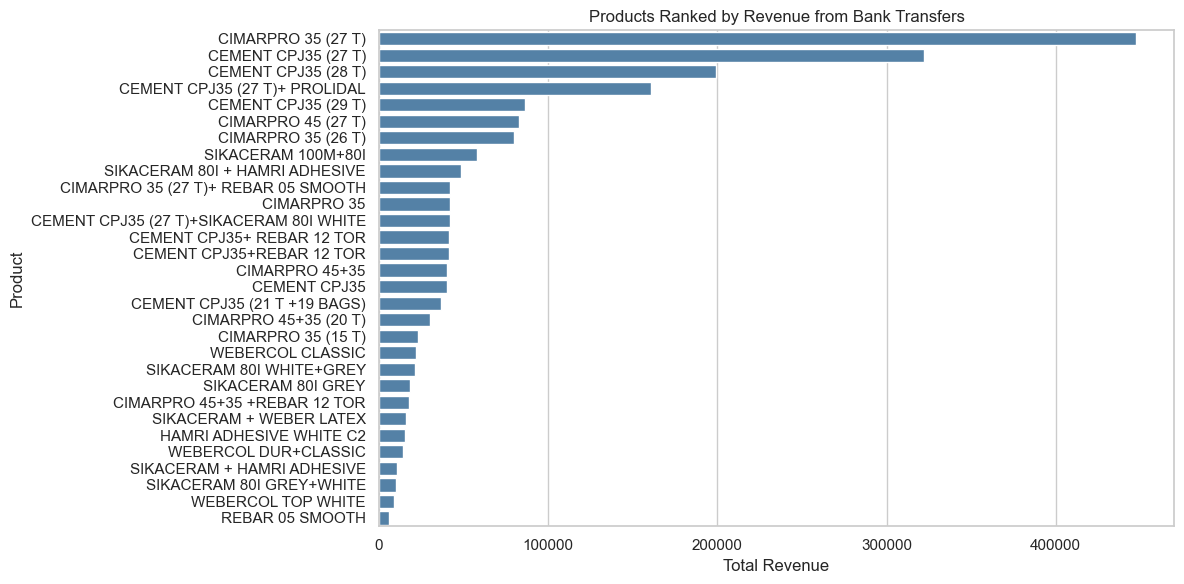

In [3]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=q1_stats,
    x="Total_Revenue",
    y="Products",
    color="steelblue"
)

plt.title("Products Ranked by Revenue from Bank Transfers")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 2. Which products are most frequently paid for using cash deposits?

In [4]:
cash_df = df[
    df["Bank_Document"].str.contains("CASH DEPOSIT", na=False)
]

q2_stats = (
    cash_df.groupby("Products")["Amount"]
    .agg(
        Transaction_Count="count",
        Total_Revenue="sum",
        Average_Transaction="mean"
    )
    .reset_index()
    .sort_values("Transaction_Count", ascending=False)
)

q2_stats

,Products,Transaction_Count,Total_Revenue,Average_Transaction
19,WEBERCOL CLASSIC WHITE,14,60484.97,4320.355000
15,WEBERCOL CLASSIC GREY,9,39522.30,4391.366667
14,SIKACERAM 80I+HAMRI ADHESIVE,8,21196.00,2649.500000
12,SIKACERAM 80I WHITE,7,30366.72,4338.102857
13,SIKACERAM 80I WHITE + GREY,5,24997.20,4999.440000
11,SIKACERAM 100M+80I,5,20552.00,4110.400000
0,GURU WATERSTOP MAT (30 M2),4,19200.00,4800.000000
8,SIKACERAM 100M GREY,4,19997.12,4999.280000
1,HAMRI ADHESIVE GREY C1,2,8899.68,4449.840000
22,WEBERCOL DUR WHITE,2,9995.62,4997.810000


## 3.Which product–payment combinations have the highest average transaction value?

In [5]:
q3_stats = (
    df.groupby(["Products", "Bank_Document"])["Amount"]
    .agg(
        Average_Transaction="mean",
        Median_Transaction="median",
        Total_Revenue="sum",
        Transaction_Count="count"
    )
    .reset_index()
    .sort_values("Average_Transaction", ascending=False)
)

q3_stats

,Products,Bank_Document,Average_Transaction,Median_Transaction,Total_Revenue,Transaction_Count
37,SIKACERAM 80I + HAMRI ADHESIVE,TRANSFER RECEIVED,48500.000000,48500.00,48500.00,1
45,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,COLLECTION OF 1 LCN,45600.000000,45600.00,45600.00,1
43,SIKACERAM 80I WHITE+GREY,COLLECTION OF 1 LCN,44800.000000,44800.00,44800.00,1
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,43210.000000,43210.00,86420.00,2
13,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,TRANSFER RECEIVED,42080.000000,42080.00,42080.00,1
9,CIMARPRO 35,TRANSFER RECEIVED,42080.000000,42080.00,42080.00,1
4,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,TRANSFER RECEIVED,41720.000000,41720.00,41720.00,1
7,CEMENT CPJ35+ REBAR 12 TOR,TRANSFER RECEIVED,41600.000000,41600.00,41600.00,1
8,CEMENT CPJ35+REBAR 12 TOR,TRANSFER RECEIVED,41445.000000,41445.00,41445.00,1
14,CIMARPRO 45 (27 T),TRANSFER RECEIVED,41310.000000,41310.00,82620.00,2


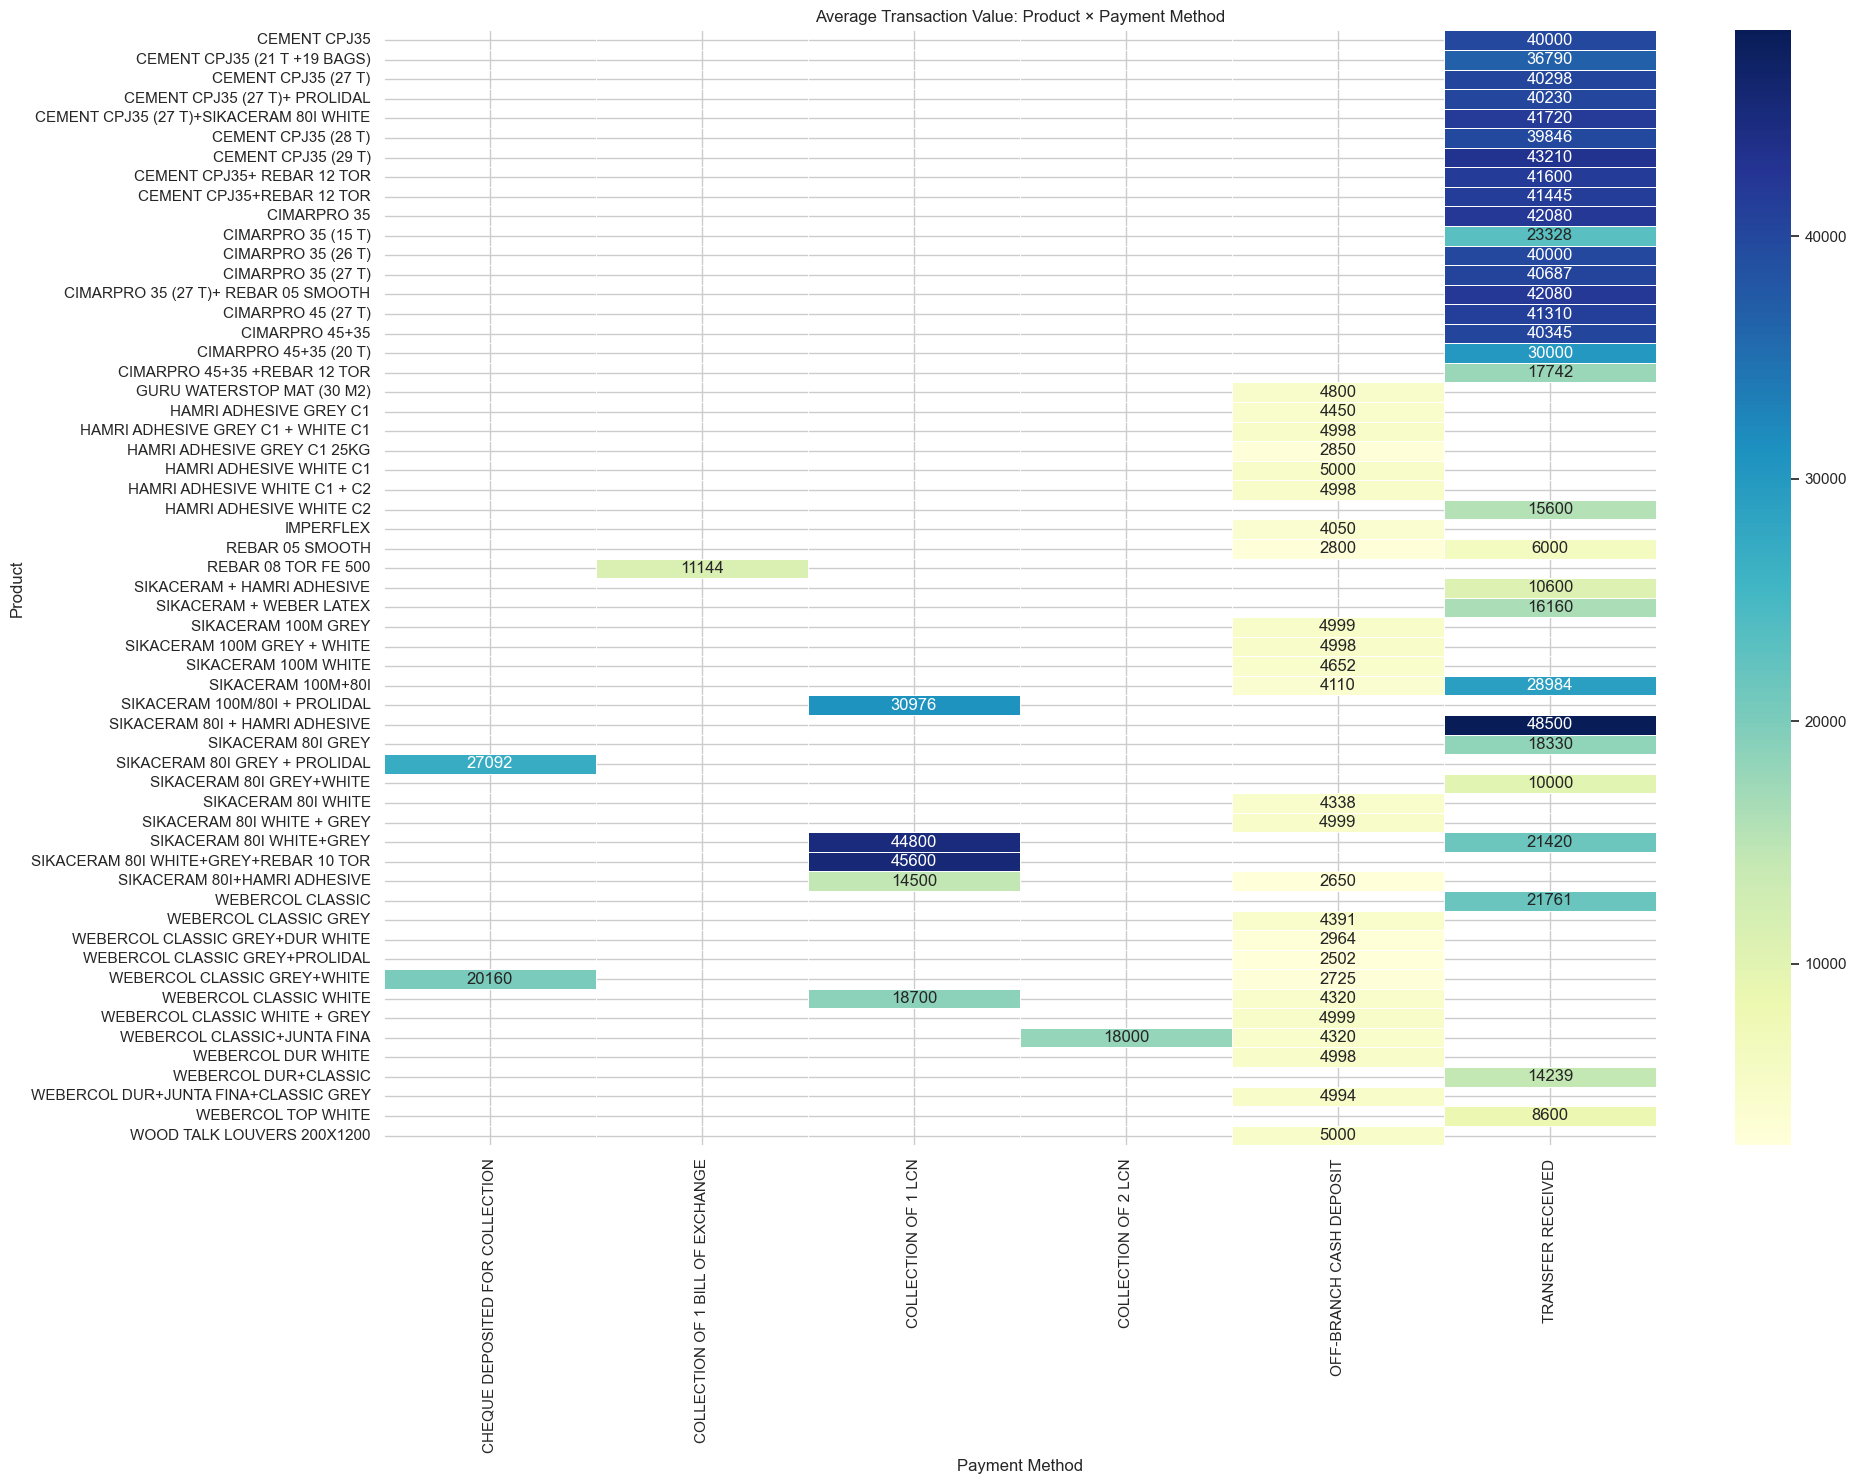

In [8]:
q3_pivot = df.pivot_table(
    index="Products",
    columns="Bank_Document",
    values="Amount",
    aggfunc="mean"
)

plt.figure(figsize=(20, 15))

sns.heatmap(
    q3_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Transaction Value: Product × Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 4. Are expensive products associated with particular payment methods?

Here, “expensive” means a transaction amount above the overall 75th percentile. Since unit prices are not available, this measures high-value transactions rather than the actual price of a product.

In [9]:
threshold = df["Amount"].quantile(0.75)

df["High_Value"] = df["Amount"] > threshold

q4_stats = (
    df.groupby(["Products", "Bank_Document"])
    .agg(
        Transaction_Count=("Amount", "size"),
        High_Value_Count=("High_Value", "sum"),
        Average_Transaction=("Amount", "mean"),
        Total_Revenue=("Amount", "sum")
    )
    .reset_index()
)

q4_stats["High_Value_Percentage"] = (
    q4_stats["High_Value_Count"] /
    q4_stats["Transaction_Count"] * 100
)

q4_stats = q4_stats.sort_values(
    "High_Value_Percentage", ascending=False
)

print("High-value threshold:", threshold)
q4_stats

High-value threshold: 40230.0


,Products,Bank_Document,Transaction_Count,High_Value_Count,Average_Transaction,Total_Revenue,High_Value_Percentage
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,2,2,43210.000000,86420.00,100.000000
7,CEMENT CPJ35+ REBAR 12 TOR,TRANSFER RECEIVED,1,1,41600.000000,41600.00,100.000000
4,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,TRANSFER RECEIVED,1,1,41720.000000,41720.00,100.000000
15,CIMARPRO 45+35,TRANSFER RECEIVED,1,1,40345.000000,40345.00,100.000000
13,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,TRANSFER RECEIVED,1,1,42080.000000,42080.00,100.000000
14,CIMARPRO 45 (27 T),TRANSFER RECEIVED,2,2,41310.000000,82620.00,100.000000
9,CIMARPRO 35,TRANSFER RECEIVED,1,1,42080.000000,42080.00,100.000000
8,CEMENT CPJ35+REBAR 12 TOR,TRANSFER RECEIVED,1,1,41445.000000,41445.00,100.000000
43,SIKACERAM 80I WHITE+GREY,COLLECTION OF 1 LCN,1,1,44800.000000,44800.00,100.000000
45,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,COLLECTION OF 1 LCN,1,1,45600.000000,45600.00,100.000000


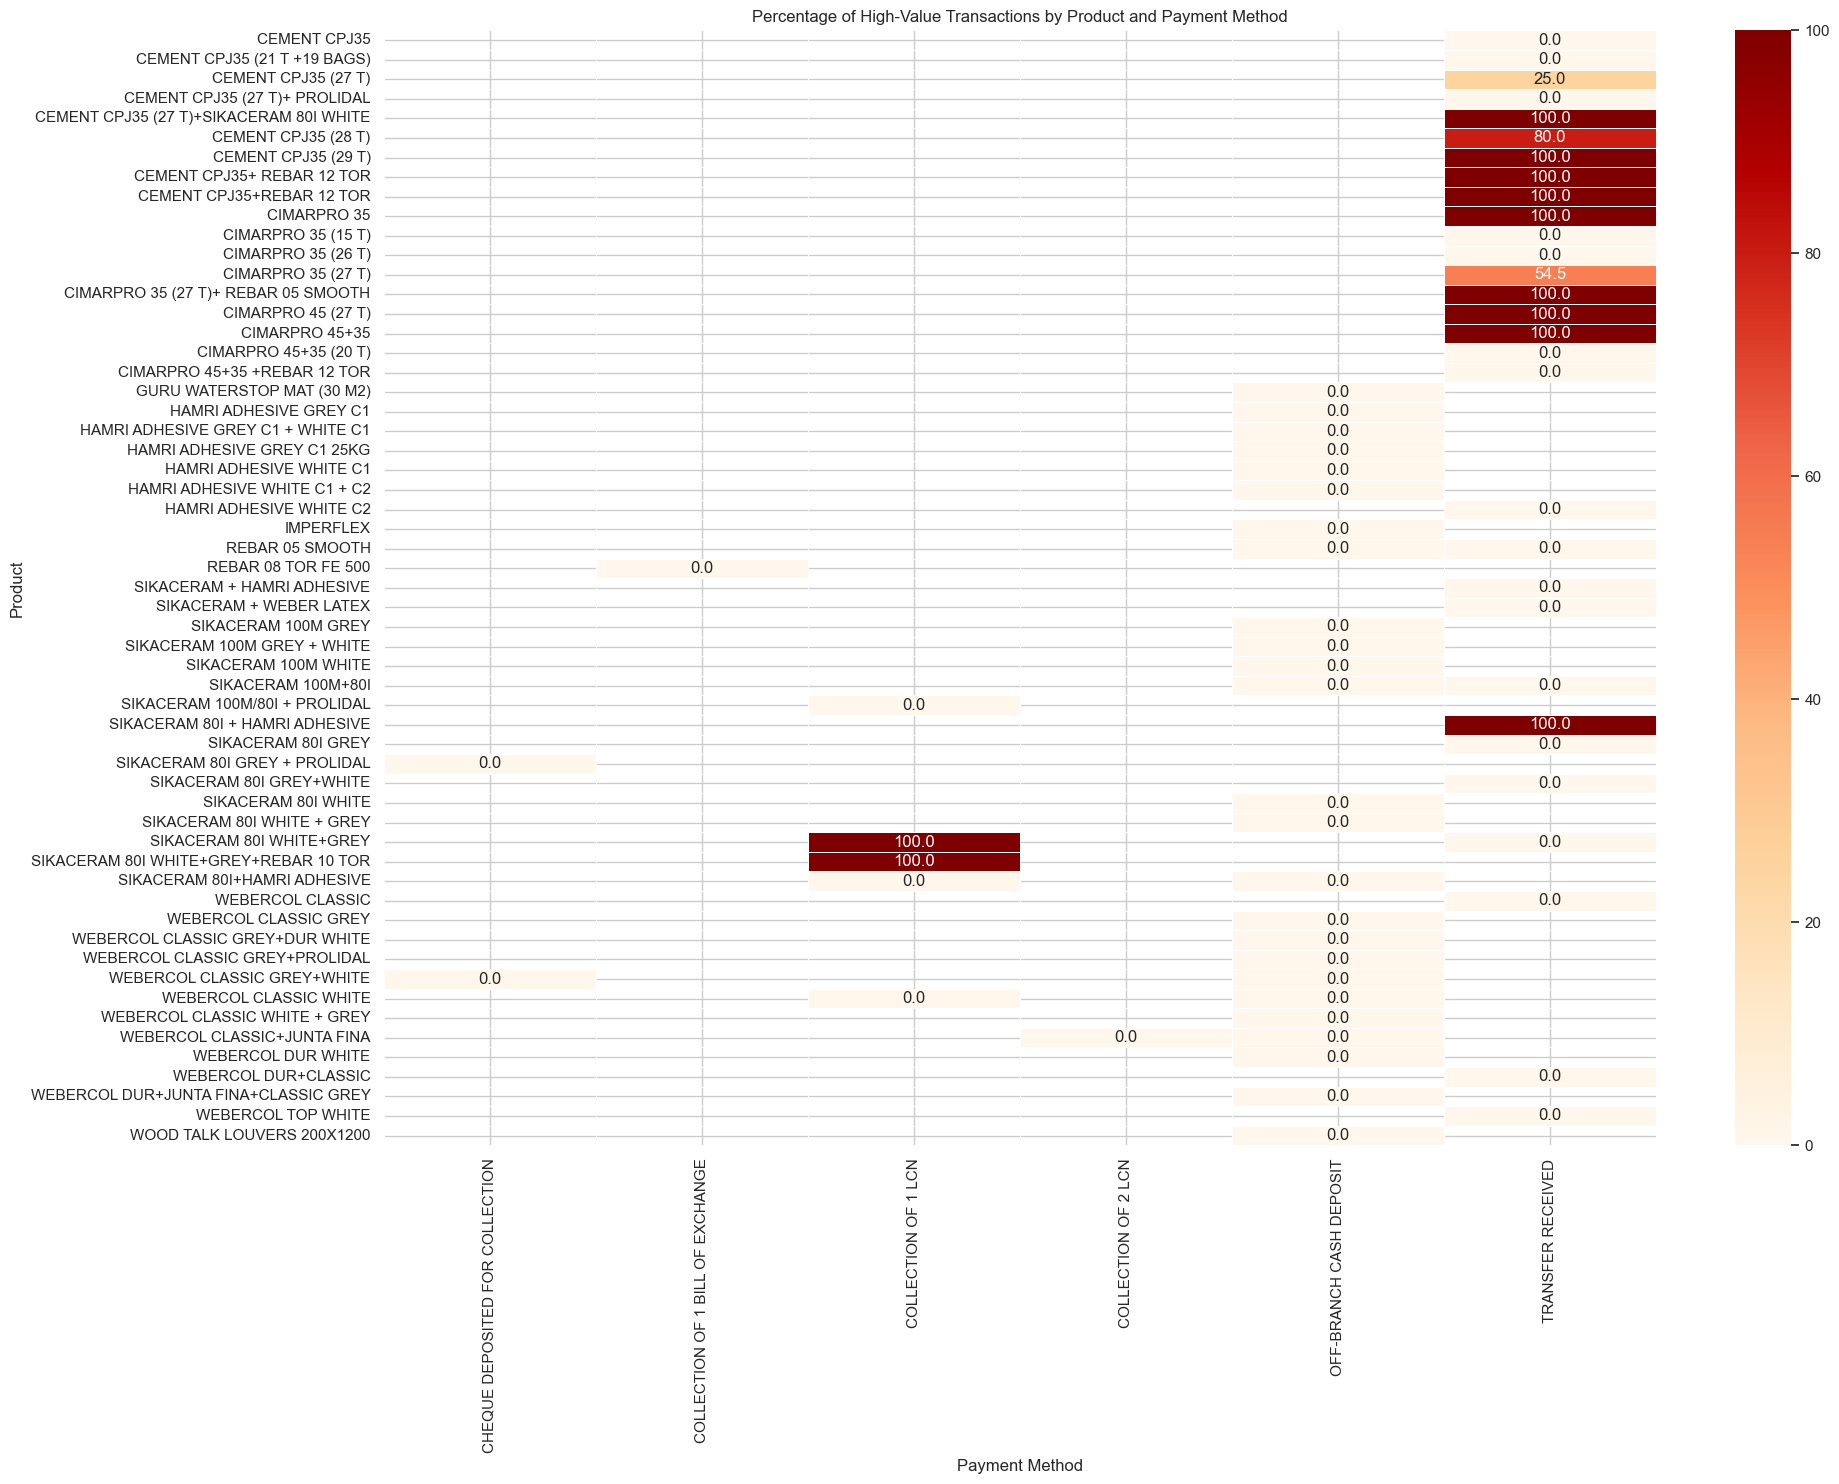

In [10]:
q4_pivot = q4_stats.pivot(
    index="Products",
    columns="Bank_Document",
    values="High_Value_Percentage"
)

plt.figure(figsize=(20, 15))

sns.heatmap(
    q4_pivot,
    annot=True,
    fmt=".1f",
    cmap="OrRd",
    linewidths=0.5
)

plt.title("Percentage of High-Value Transactions by Product and Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 5. Does payment behavior differ depending on the product purchased?

In [11]:
q5_stats = (
    df.groupby(["Products", "Bank_Document"])
    .size()
    .reset_index(name="Transaction_Count")
)

q5_stats["Product_Total_Transactions"] = (
    q5_stats.groupby("Products")["Transaction_Count"].transform("sum")
)

q5_stats["Payment_Percentage"] = (
    q5_stats["Transaction_Count"] /
    q5_stats["Product_Total_Transactions"] * 100
)

q5_stats.sort_values(
    ["Products", "Payment_Percentage"],
    ascending=[True, False]
)

,Products,Bank_Document,Transaction_Count,Product_Total_Transactions,Payment_Percentage
0,CEMENT CPJ35,TRANSFER RECEIVED,1,1,100.000000
1,CEMENT CPJ35 (21 T +19 BAGS),TRANSFER RECEIVED,1,1,100.000000
2,CEMENT CPJ35 (27 T),TRANSFER RECEIVED,8,8,100.000000
3,CEMENT CPJ35 (27 T)+ PROLIDAL,TRANSFER RECEIVED,4,4,100.000000
4,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,TRANSFER RECEIVED,1,1,100.000000
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,5,5,100.000000
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,2,2,100.000000
7,CEMENT CPJ35+ REBAR 12 TOR,TRANSFER RECEIVED,1,1,100.000000
8,CEMENT CPJ35+REBAR 12 TOR,TRANSFER RECEIVED,1,1,100.000000
9,CIMARPRO 35,TRANSFER RECEIVED,1,1,100.000000


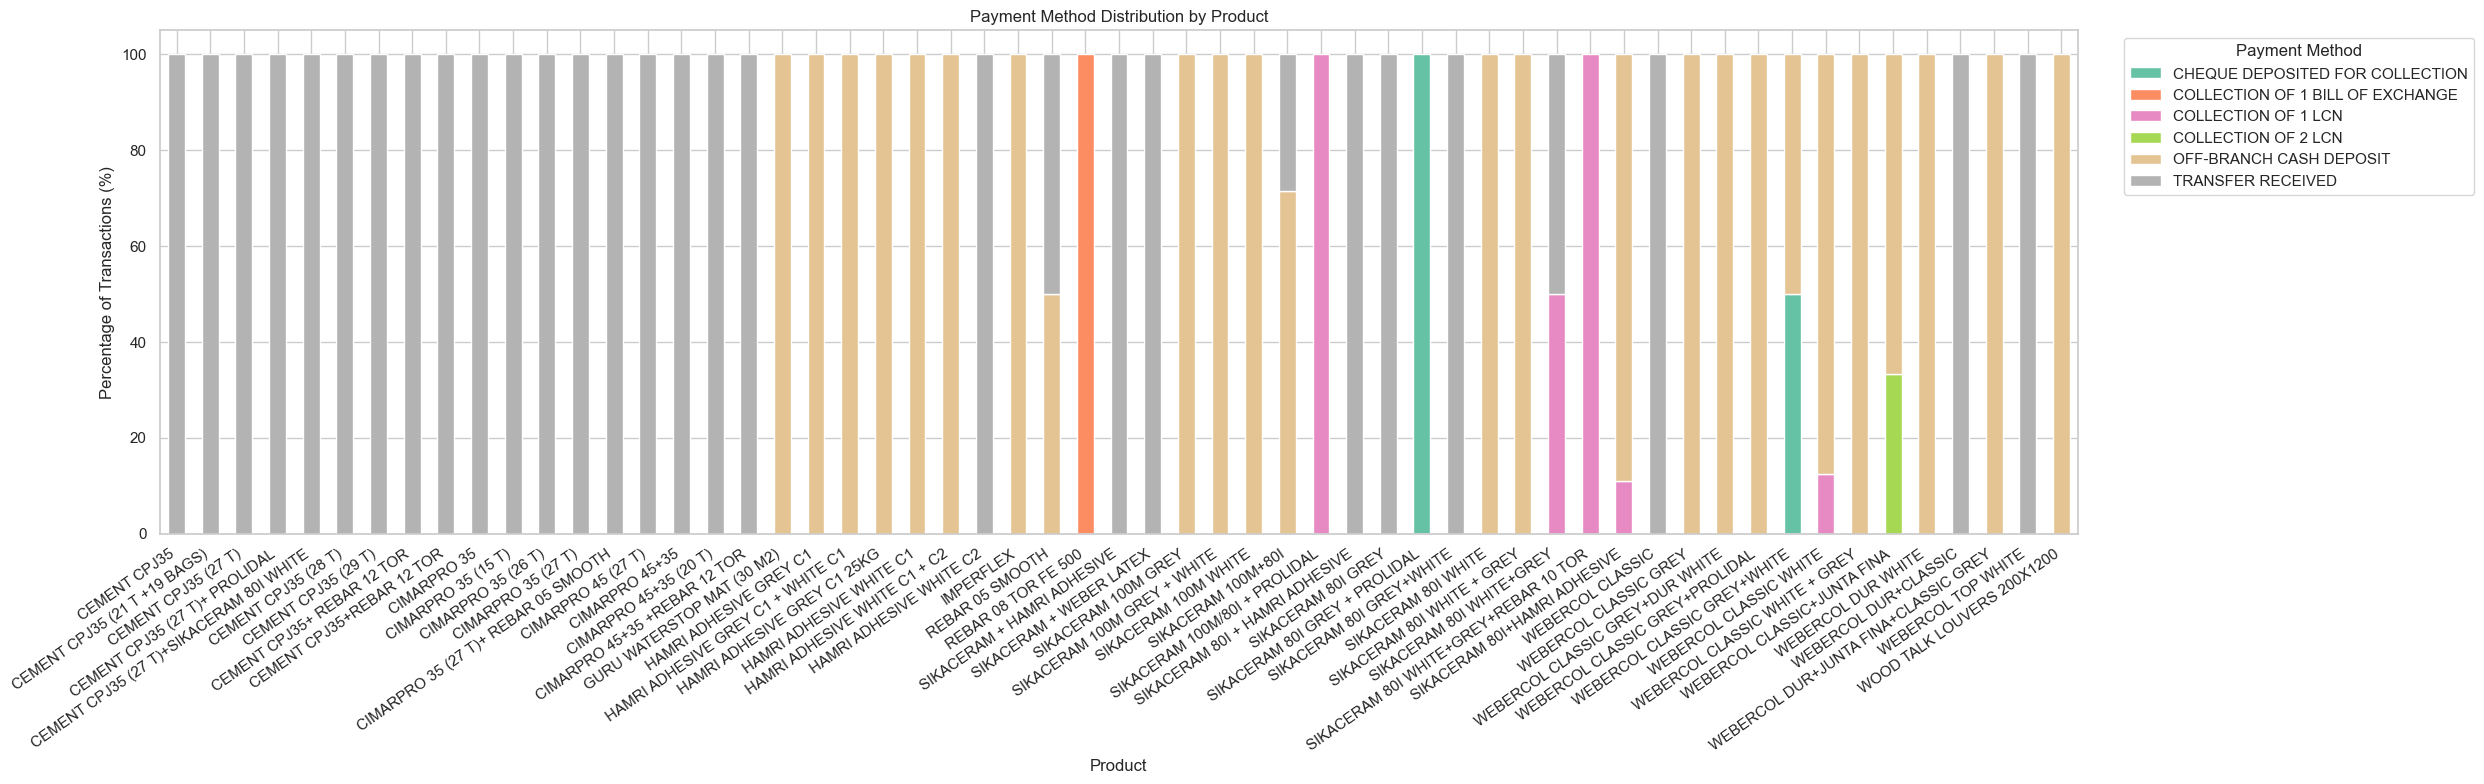

In [19]:
q5_pivot = q5_stats.pivot(
    index="Products",
    columns="Bank_Document",
    values="Payment_Percentage"
).fillna(0)

q5_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(25,8),
    colormap="Set2"
)

plt.title("Payment Method Distribution by Product")
plt.xlabel("Product")
plt.ylabel("Percentage of Transactions (%)")
plt.legend(title="Payment Method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Which payment methods contribute the largest percentage of each product's total revenue?

In [21]:
q6_stats = (
    df.groupby(["Products", "Bank_Document"])["Amount"]
    .sum()
    .reset_index(name="Payment_Revenue")
)

q6_stats["Product_Total_Revenue"] = (
    q6_stats.groupby("Products")["Payment_Revenue"].transform("sum")
)

q6_stats["Revenue_Percentage"] = (
    q6_stats["Payment_Revenue"] /
    q6_stats["Product_Total_Revenue"] * 100
)

q6_top = q6_stats.loc[
    q6_stats.groupby("Products")["Revenue_Percentage"].idxmax()
]

print("Largest revenue-contributing payment method for each product:")
q6_top.sort_values("Revenue_Percentage", ascending=False)



Largest revenue-contributing payment method for each product:


,Products,Bank_Document,Payment_Revenue,Product_Total_Revenue,Revenue_Percentage
0,CEMENT CPJ35,TRANSFER RECEIVED,40000.00,40000.00,100.000000
1,CEMENT CPJ35 (21 T +19 BAGS),TRANSFER RECEIVED,36790.00,36790.00,100.000000
2,CEMENT CPJ35 (27 T),TRANSFER RECEIVED,322380.00,322380.00,100.000000
3,CEMENT CPJ35 (27 T)+ PROLIDAL,TRANSFER RECEIVED,160920.00,160920.00,100.000000
4,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,TRANSFER RECEIVED,41720.00,41720.00,100.000000
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,199230.00,199230.00,100.000000
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,86420.00,86420.00,100.000000
7,CEMENT CPJ35+ REBAR 12 TOR,TRANSFER RECEIVED,41600.00,41600.00,100.000000
8,CEMENT CPJ35+REBAR 12 TOR,TRANSFER RECEIVED,41445.00,41445.00,100.000000
9,CIMARPRO 35,TRANSFER RECEIVED,42080.00,42080.00,100.000000


## 7. Which products have the highest and lowest transaction values within each payment method?

In [24]:
q7_stats = (
    df.groupby(["Products", "Bank_Document"])["Amount"]
    .agg(
        Highest_Transaction="max",
        Lowest_Transaction="min",
        Average_Transaction="mean",
        Transaction_Count="count"
    )
    .reset_index()
)

print("Highest transaction values:")

q7_stats.sort_values("Highest_Transaction", ascending=False).groupby("Bank_Document", group_keys=False).head(5)




Highest transaction values:


,Products,Bank_Document,Highest_Transaction,Lowest_Transaction,Average_Transaction,Transaction_Count
37,SIKACERAM 80I + HAMRI ADHESIVE,TRANSFER RECEIVED,48500.00,48500.00,48500.000000,1
45,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,COLLECTION OF 1 LCN,45600.00,45600.00,45600.000000,1
43,SIKACERAM 80I WHITE+GREY,COLLECTION OF 1 LCN,44800.00,44800.00,44800.000000,1
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,43210.00,43210.00,43210.000000,2
13,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,TRANSFER RECEIVED,42080.00,42080.00,42080.000000,1
9,CIMARPRO 35,TRANSFER RECEIVED,42080.00,42080.00,42080.000000,1
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,41720.00,32350.00,39846.000000,5
39,SIKACERAM 80I GREY + PROLIDAL,CHEQUE DEPOSITED FOR COLLECTION,31625.00,22560.00,27092.500000,2
36,SIKACERAM 100M/80I + PROLIDAL,COLLECTION OF 1 LCN,30976.00,30976.00,30976.000000,1
54,WEBERCOL CLASSIC WHITE,COLLECTION OF 1 LCN,24900.00,12500.00,18700.000000,2


In [25]:
print("\nLowest transaction values:")

q7_stats.sort_values("Lowest_Transaction").groupby("Bank_Document", group_keys=False).head(3)



Lowest transaction values:


,Products,Bank_Document,Highest_Transaction,Lowest_Transaction,Average_Transaction,Transaction_Count
41,SIKACERAM 80I WHITE,OFF-BRANCH CASH DEPOSIT,4999.68,384.0,4338.102857,7
55,WEBERCOL CLASSIC WHITE,OFF-BRANCH CASH DEPOSIT,4998.24,2160.0,4320.355000,14
51,WEBERCOL CLASSIC GREY+PROLIDAL,OFF-BRANCH CASH DEPOSIT,2502.00,2502.0,2502.000000,1
27,REBAR 05 SMOOTH,TRANSFER RECEIVED,6000.00,6000.0,6000.000000,1
62,WEBERCOL TOP WHITE,TRANSFER RECEIVED,8600.00,8600.0,8600.000000,1
40,SIKACERAM 80I GREY+WHITE,TRANSFER RECEIVED,10000.00,10000.0,10000.000000,1
28,REBAR 08 TOR FE 500,COLLECTION OF 1 BILL OF EXCHANGE,11144.00,11144.0,11144.000000,1
54,WEBERCOL CLASSIC WHITE,COLLECTION OF 1 LCN,24900.00,12500.0,18700.000000,2
46,SIKACERAM 80I+HAMRI ADHESIVE,COLLECTION OF 1 LCN,14500.00,14500.0,14500.000000,1
57,WEBERCOL CLASSIC+JUNTA FINA,COLLECTION OF 2 LCN,18000.00,18000.0,18000.000000,1


## 8. Which product–payment combinations have the most transactions, and does higher transaction frequency correspond to greater revenue?

In [27]:
q8_stats = (
    df.groupby(["Products", "Bank_Document"])["Amount"]
    .agg(
        Transaction_Count="count",
        Total_Revenue="sum",
        Average_Transaction="mean"
    )
    .reset_index()
    .sort_values("Transaction_Count", ascending=False)
)

q8_stats



,Products,Bank_Document,Transaction_Count,Total_Revenue,Average_Transaction
55,WEBERCOL CLASSIC WHITE,OFF-BRANCH CASH DEPOSIT,14,60484.97,4320.355000
12,CIMARPRO 35 (27 T),TRANSFER RECEIVED,11,447555.00,40686.818182
49,WEBERCOL CLASSIC GREY,OFF-BRANCH CASH DEPOSIT,9,39522.30,4391.366667
2,CEMENT CPJ35 (27 T),TRANSFER RECEIVED,8,322380.00,40297.500000
47,SIKACERAM 80I+HAMRI ADHESIVE,OFF-BRANCH CASH DEPOSIT,8,21196.00,2649.500000
41,SIKACERAM 80I WHITE,OFF-BRANCH CASH DEPOSIT,7,30366.72,4338.102857
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,5,199230.00,39846.000000
34,SIKACERAM 100M+80I,OFF-BRANCH CASH DEPOSIT,5,20552.00,4110.400000
42,SIKACERAM 80I WHITE + GREY,OFF-BRANCH CASH DEPOSIT,5,24997.20,4999.440000
18,GURU WATERSTOP MAT (30 M2),OFF-BRANCH CASH DEPOSIT,4,19200.00,4800.000000


In [28]:
# Pearson correlation across product-payment combinations
if len(q8_stats) >= 2:
    correlation = q8_stats[
        ["Transaction_Count", "Total_Revenue"]
    ].corr().iloc[0, 1]

    print("\nCorrelation between transaction count and total revenue:",
          round(correlation, 3))


Correlation between transaction count and total revenue: 0.563


## 9. Are high-value transactions concentrated in particular product–payment combinations?

In [31]:
threshold = df["Amount"].quantile(0.75)

df["High_Value"] = df["Amount"] > threshold

q9_stats = (
    df.groupby(["Products", "Bank_Document"])
    .agg(
        Transaction_Count=("Amount", "size"),
        High_Value_Count=("High_Value", "sum"),
        Total_Revenue=("Amount", "sum")
    )
    .reset_index()
)

q9_stats["High_Value_Percentage"] = (
    q9_stats["High_Value_Count"] /
    q9_stats["Transaction_Count"] * 100
)

q9_stats = q9_stats.sort_values(
    ["High_Value_Count", "High_Value_Percentage"],
    ascending=False
)

print("High-value threshold:", threshold)
q9_stats

High-value threshold: 40230.0


,Products,Bank_Document,Transaction_Count,High_Value_Count,Total_Revenue,High_Value_Percentage
12,CIMARPRO 35 (27 T),TRANSFER RECEIVED,11,6,447555.00,54.545455
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,5,4,199230.00,80.000000
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,2,2,86420.00,100.000000
14,CIMARPRO 45 (27 T),TRANSFER RECEIVED,2,2,82620.00,100.000000
2,CEMENT CPJ35 (27 T),TRANSFER RECEIVED,8,2,322380.00,25.000000
4,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,TRANSFER RECEIVED,1,1,41720.00,100.000000
7,CEMENT CPJ35+ REBAR 12 TOR,TRANSFER RECEIVED,1,1,41600.00,100.000000
8,CEMENT CPJ35+REBAR 12 TOR,TRANSFER RECEIVED,1,1,41445.00,100.000000
9,CIMARPRO 35,TRANSFER RECEIVED,1,1,42080.00,100.000000
13,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,TRANSFER RECEIVED,1,1,42080.00,100.000000


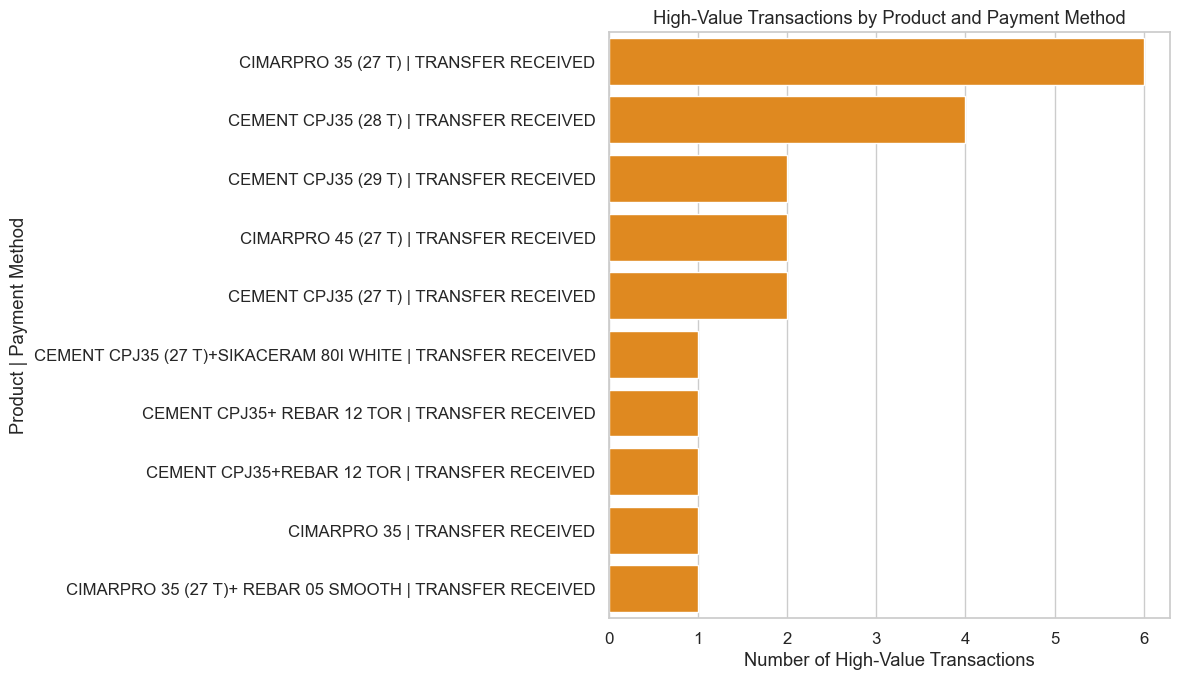

In [32]:
q9_plot = q9_stats.nlargest(10, "High_Value_Count").copy()

q9_plot["Combination"] = (
    q9_plot["Products"] + " | " + q9_plot["Bank_Document"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=q9_plot,
    x="High_Value_Count",
    y="Combination",
    color="darkorange"
)

plt.title("High-Value Transactions by Product and Payment Method")
plt.xlabel("Number of High-Value Transactions")
plt.ylabel("Product | Payment Method")
plt.tight_layout()
plt.show()

## 10. Which product–payment combinations show the greatest variability in transaction amounts, and which have the most consistent values?

In [33]:
q10_stats = (
    df.groupby(["Products", "Bank_Document"])["Amount"]
    .agg(
        Average_Transaction="mean",
        Median_Transaction="median",
        Standard_Deviation="std",
        Transaction_Count="count"
    )
    .reset_index()
)

q10_stats["CV_Percentage"] = (
    q10_stats["Standard_Deviation"] /
    q10_stats["Average_Transaction"].abs() * 100
)

# Exclude combinations with insufficient observations
q10_valid = q10_stats[
    (q10_stats["Transaction_Count"] >= 2) &
    (q10_stats["Average_Transaction"] != 0)
].copy()

q10_variable = q10_valid.nlargest(10, "Standard_Deviation")
q10_consistent = q10_valid.nsmallest(10, "CV_Percentage")

print("Most variable product-payment combinations:")
q10_variable


Most variable product-payment combinations:


,Products,Bank_Document,Average_Transaction,Median_Transaction,Standard_Deviation,Transaction_Count,CV_Percentage
54,WEBERCOL CLASSIC WHITE,COLLECTION OF 1 LCN,18700.000000,18700.00,8768.124087,2,46.888364
39,SIKACERAM 80I GREY + PROLIDAL,CHEQUE DEPOSITED FOR COLLECTION,27092.500000,27092.50,6409.922971,2,23.659400
5,CEMENT CPJ35 (28 T),TRANSFER RECEIVED,39846.000000,41720.00,4190.391390,5,10.516467
41,SIKACERAM 80I WHITE,OFF-BRANCH CASH DEPOSIT,4338.102857,4999.68,1743.599228,7,40.192667
35,SIKACERAM 100M+80I,TRANSFER RECEIVED,28983.500000,28983.50,1437.548086,2,4.959884
55,WEBERCOL CLASSIC WHITE,OFF-BRANCH CASH DEPOSIT,4320.355000,4550.72,953.700393,14,22.074584
19,HAMRI ADHESIVE GREY C1,OFF-BRANCH CASH DEPOSIT,4449.840000,4449.84,777.591185,2,17.474588
33,SIKACERAM 100M WHITE,OFF-BRANCH CASH DEPOSIT,4652.360000,4652.36,490.279558,2,10.538298
49,WEBERCOL CLASSIC GREY,OFF-BRANCH CASH DEPOSIT,4391.366667,4178.50,467.583651,9,10.647793
12,CIMARPRO 35 (27 T),TRANSFER RECEIVED,40686.818182,40800.00,461.520708,11,1.134325


In [34]:
print("\nMost consistent product-payment combinations:")
q10_consistent


Most consistent product-payment combinations:


,Products,Bank_Document,Average_Transaction,Median_Transaction,Standard_Deviation,Transaction_Count,CV_Percentage
3,CEMENT CPJ35 (27 T)+ PROLIDAL,TRANSFER RECEIVED,40230.00,40230.00,0.00000,4,0.000000
6,CEMENT CPJ35 (29 T),TRANSFER RECEIVED,43210.00,43210.00,0.00000,2,0.000000
11,CIMARPRO 35 (26 T),TRANSFER RECEIVED,40000.00,40000.00,0.00000,2,0.000000
14,CIMARPRO 45 (27 T),TRANSFER RECEIVED,41310.00,41310.00,0.00000,2,0.000000
18,GURU WATERSTOP MAT (30 M2),OFF-BRANCH CASH DEPOSIT,4800.00,4800.00,0.00000,4,0.000000
31,SIKACERAM 100M GREY,OFF-BRANCH CASH DEPOSIT,4999.28,4999.28,0.00000,4,0.000000
34,SIKACERAM 100M+80I,OFF-BRANCH CASH DEPOSIT,4110.40,4110.40,0.00000,5,0.000000
58,WEBERCOL CLASSIC+JUNTA FINA,OFF-BRANCH CASH DEPOSIT,4320.00,4320.00,0.00000,2,0.000000
59,WEBERCOL DUR WHITE,OFF-BRANCH CASH DEPOSIT,4997.81,4997.81,0.00000,2,0.000000
42,SIKACERAM 80I WHITE + GREY,OFF-BRANCH CASH DEPOSIT,4999.44,4999.68,0.43359,5,0.008673


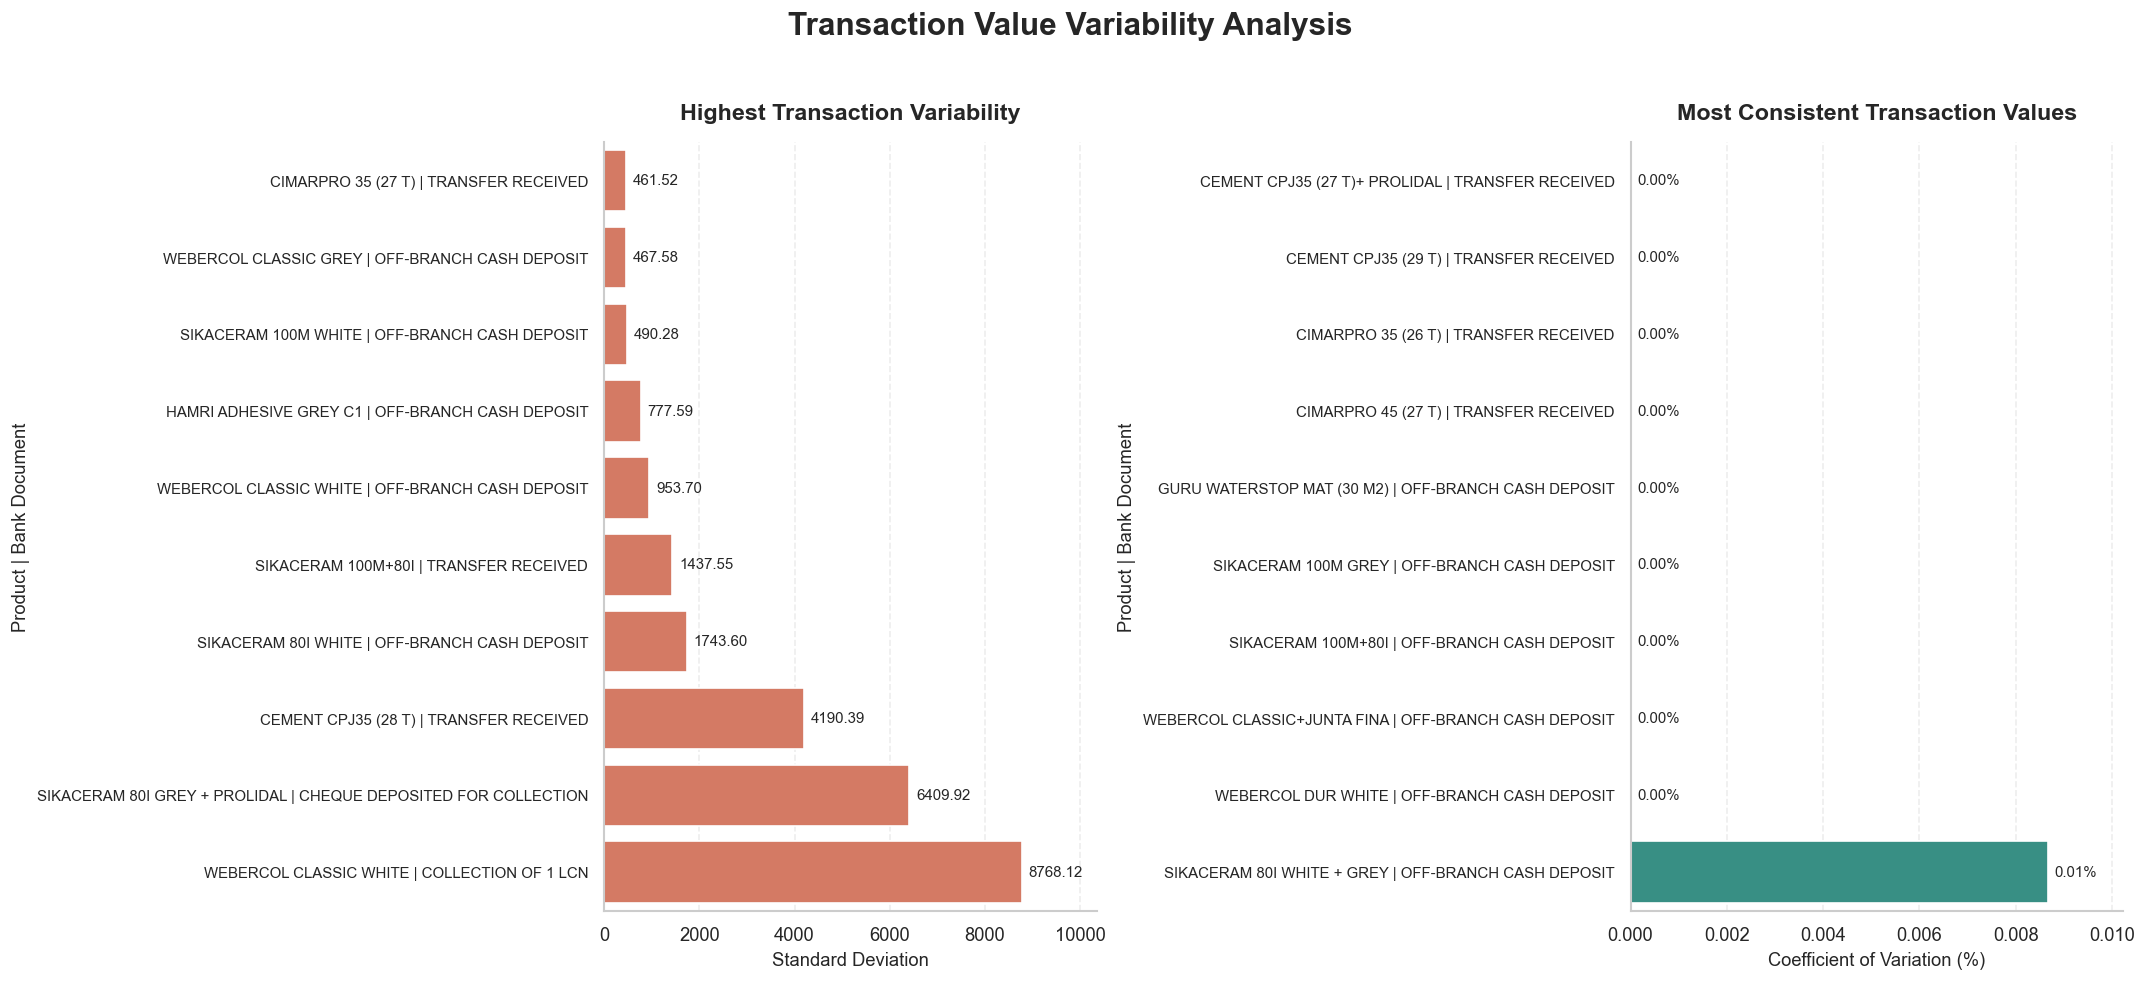

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Create independent copies
q10_variable = q10_variable.copy()
q10_consistent = q10_consistent.copy()

# Create readable category labels
q10_variable["Combination"] = (
    q10_variable["Products"].astype(str)
    + " | "
    + q10_variable["Bank_Document"].astype(str)
)

q10_consistent["Combination"] = (
    q10_consistent["Products"].astype(str)
    + " | "
    + q10_consistent["Bank_Document"].astype(str)
)

# Sort values for better comparison
q10_variable = q10_variable.sort_values(
    "Standard_Deviation", ascending=True
)

q10_consistent = q10_consistent.sort_values(
    "CV_Percentage", ascending=True
)

# Professional plotting theme
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=120)

fig.suptitle(
    "Transaction Value Variability Analysis",
    fontsize=19,
    fontweight="bold",
    y=1.02
)

# Left chart: Highest transaction variability
sns.barplot(
    data=q10_variable,
    x="Standard_Deviation",
    y="Combination",
    color="#E76F51",
    ax=axes[0]
)

axes[0].set_title(
    "Highest Transaction Variability",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[0].set_xlabel("Standard Deviation", fontsize=11)
axes[0].set_ylabel("Product | Bank Document", fontsize=11)

# Add value labels
for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=9
    )

# Right chart: Most consistent transaction values
sns.barplot(
    data=q10_consistent,
    x="CV_Percentage",
    y="Combination",
    color="#2A9D8F",
    ax=axes[1]
)

axes[1].set_title(
    "Most Consistent Transaction Values",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[1].set_xlabel("Coefficient of Variation (%)", fontsize=11)
axes[1].set_ylabel("Product | Bank Document", fontsize=11)

# Add percentage labels
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.2f%%",
        padding=4,
        fontsize=9
    )

# Refine both charts
for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=9)
    ax.margins(x=0.18)

plt.tight_layout()
plt.show()